In [1]:
import numpy as np
from geopandas import read_file as gpd_read_file
from matplotlib import pyplot as plt
from demprepfly import prep_dem, reproj_dem, detect_crevasses

In [ ]:
4979

In [49]:
from pyproj import CRS

In [55]:
CRS.from_epsg(4979).is_vertical

False

In [4]:
input_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_32632_1m.tif"
output_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_4326.tif"

dem, mask = prep_dem(input_tif, from_vert_epsg='ellipsoid', to_vert_epsg=4326)

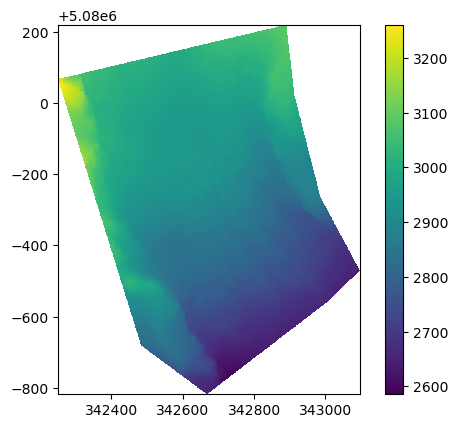

In [5]:
plt.pcolormesh(dem.x, dem.y, dem)
plt.gca().set_aspect(1)
plt.colorbar()

In [27]:
import argparse
import os

import numpy as np
import rioxarray
import xarray as xr
from geopandas import read_file as gpd_read_file
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.fill import fillnodata
from skimage.morphology import closing, disk
from scipy.ndimage import gaussian_filter, binary_dilation
from pyproj import CRS, Transformer, network

def reproj_dem(dem, from_horiz_epsg=None, to_horiz_epsg=None, from_vert_epsg=None, to_vert_epsg=None,
               n_samples=10, resampling=Resampling.bilinear):
    """Reprojects a DEM horizontally and vertically.

    The vertical transformation is computed with pyproj on a coarse grid of n_samples x n_samples
    points of the DEM (spanning its full extent), linearly interpolated to all pixels and added
    to the DEM. This is accurate as long as the vertical shift varies smoothly (e.g. geoid models).
    The horizontal reprojection is then done with rio.reproject.

    Args:
        dem: 2D rioxarray DataArray of elevations, with x / y coordinates in from_horiz_epsg.
        from_horiz_epsg: EPSG code of the horizontal CRS of dem (e.g. 32632). Defaults to None.
        to_horiz_epsg: EPSG code of the target horizontal CRS (e.g. 4326). Defaults to None.
            If both horizontal codes are None, no horizontal reprojection is done and the CRS of dem is used.
        from_vert_epsg: EPSG code of the vertical CRS of dem (e.g. 3855 for EGM2008 heights),
            or "ellipsoid" for ellipsoidal heights. Defaults to None.
        to_vert_epsg: EPSG code of the target vertical CRS, or "ellipsoid" for ellipsoidal heights.
            Defaults to None. If both vertical codes are None, no vertical transformation is done.
        n_samples: Number of sample points per axis for computing the vertical shift. Defaults to 10.
        resampling: Resampling method for the horizontal reprojection. Defaults to Resampling.bilinear.

    Raises:
        ValueError: If only one of from_horiz_epsg and to_horiz_epsg is given.
        ValueError: If only one of from_vert_epsg and to_vert_epsg is given.
        ValueError: If a vertical transformation is requested but neither horizontal codes are given
            nor dem has a CRS.
        pyproj.exceptions.ProjError: If the vertical transformation is not available, e.g. because
            the required geoid grid can't be found or downloaded.

    Returns:
        Reprojected DEM as rioxarray DataArray.
    """
    if (from_horiz_epsg is None) != (to_horiz_epsg is None):
        raise ValueError("from_horiz_epsg and to_horiz_epsg must both be given or both be None.")

    if (from_vert_epsg is None) != (to_vert_epsg is None):
        raise ValueError("from_vert_epsg and to_vert_epsg must both be given or both be None. "
                         "Use 'ellipsoid' for ellipsoidal heights.")

    if from_horiz_epsg is not None:
        dem = dem.rio.write_crs(f"EPSG:{from_horiz_epsg}")
        from_horiz_crs, to_horiz_crs = CRS.from_epsg(from_horiz_epsg), CRS.from_epsg(to_horiz_epsg)
    elif dem.rio.crs is not None:
        from_horiz_crs = to_horiz_crs = CRS(dem.rio.crs)
    else:
        from_horiz_crs = to_horiz_crs = None

    if from_vert_epsg != to_vert_epsg:
        if from_horiz_crs is None:
            raise ValueError("dem has no CRS. Provide from_horiz_epsg and to_horiz_epsg for the vertical transformation.")

        # build compound CRS. For ellipsoidal heights, the 3D version of the horizontal CRS is used.
        def crs_3d(horiz_crs, vert_epsg):
            if vert_epsg == "ellipsoid":
                return horiz_crs.to_3d()
            return CRS(f"EPSG:{horiz_crs.to_epsg()}+{vert_epsg}")

        network.set_network_enabled(True)  # allows PROJ to download missing geoid grids
        # only_best: raise an error instead of silently falling back to a transformation without vertical shift
        transformer = Transformer.from_crs(crs_3d(from_horiz_crs, from_vert_epsg),
                                           crs_3d(to_horiz_crs, to_vert_epsg),
                                           always_xy=True, only_best=True)

        # sample grid spanning the full dem, heights taken from the dem
        xs = np.linspace(dem.x.values[0], dem.x.values[-1], n_samples)
        ys = np.linspace(dem.y.values[0], dem.y.values[-1], n_samples)
        z = dem.sel(x=xs, y=ys, method="nearest").values.astype(np.float64)
        z[np.isnan(z)] = np.nanmedian(z) if np.any(~np.isnan(z)) else 0.0
        x, y = np.meshgrid(xs, ys)

        _, _, z_new = transformer.transform(x, y, z)
        dz = xr.DataArray(z_new - z, coords={"y": ys, "x": xs}, dims=("y", "x"))

        # interpolate vertical shifts to all pixels and add them (copy keeps encoding / nodata)
        dz = dz.interp(x=dem.x, y=dem.y).values
        dem = dem.copy(data=(dem.values + dz).astype(dem.dtype))

    if from_horiz_epsg is not None and from_horiz_epsg != to_horiz_epsg:
        dem = dem.rio.reproject(f"EPSG:{to_horiz_epsg}", resampling=resampling)

    return dem

In [29]:
import rioxarray

input_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_32632_1m.tif"
output_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_4326.tif"

dem = rioxarray.open_rasterio(input_tif, masked=True).sel(band=1)

#dem_4326.rio.to_raster(output_tif)

In [38]:
dem2 = reproj_dem(dem, from_horiz_epsg=32632, from_vert_epsg='ellipsoid', to_horiz_epsg=2056, to_vert_epsg=5729)

c:\Users\jkolar\AppData\Local\anaconda3\envs\geo\Lib\site-packages\pyproj\crs\_cf1x8.py:515: UserWarning: angle from rectified to skew grid parameter lost in conversion to CF
  warnings.warn(


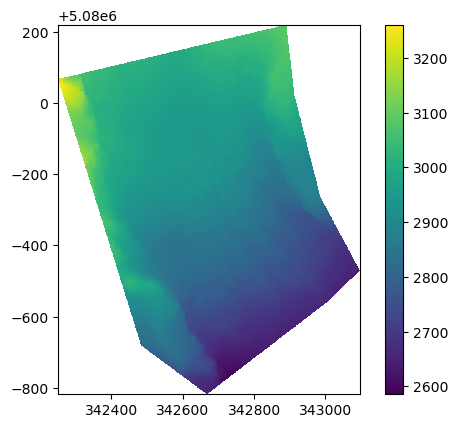

In [39]:
plt.pcolormesh(dem.x, dem.y, dem)
plt.gca().set_aspect(1)
plt.colorbar()

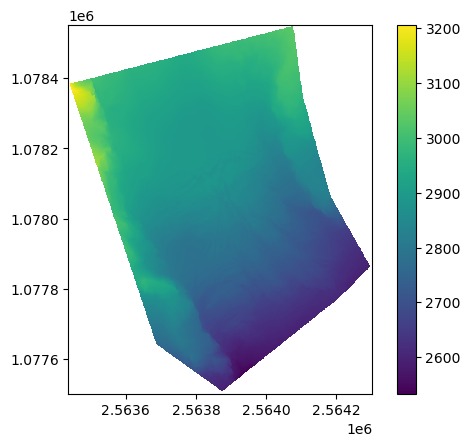

In [40]:
plt.pcolormesh(dem2.x, dem2.y, dem2)
plt.gca().set_aspect(1)
plt.colorbar()

In [41]:
dem - dem2

<xarray.DataArray (y: 0, x: 0)> Size: 0B
array([], shape=(0, 0), dtype=float32)
Coordinates:
  * y            (y) float64 0B 
  * x            (x) float64 0B 
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [ ]:
transformer = Transformer.from_crs(4326, to_epsg, always_xy=True, only_best=True)

In [ ]:
from pyproj import Transformer

def reproj_dem(dem, from_epsg, to_epsg):
    x, y, z = dem.x.mean(), dem.y.mean(), dem.mean()

    transformer = Transformer.from_crs(from_epsg, to_epsg, always_xy=True, only_best=True)
    x_new, y_new, z_new = transformer(x,y,z)

    dz = z_new - z

    


In [18]:
x, y = np.meshgrid(dem.x, dem.y)
z = np.array(dem)

In [ ]:
py

(1037, 846)

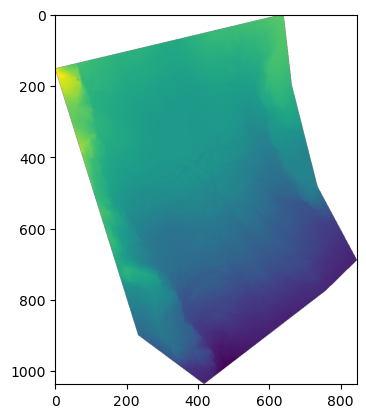

In [6]:
plt.imshow(dem[0])

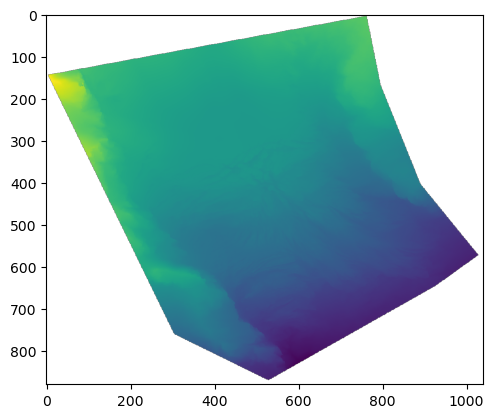

In [7]:
plt.imshow(dem_4326[0])